# COS801: Deep Learning on Tabular Data for Fraud Detection under Extreme Class Imbalance

## Notebook 01: Data Understanding and Exploratory Data Analysis

**Module:** COS801 - Deep Learning

**Project Code:** PJT10

**Dataset:** IEEE-CIS Fraud Detection (Kaggle)

### Project Overview

This notebook begins with the investigation of fraud detection using tabular transaction data. The purpose is to understand the dataset and examine the distribution of fraudulent as well as legitimate transactions, identify missing values, and explore important transaction characteristics before developing the machine learning and deep learning models.

### Objectives of This Notebook

1. Load the IEEE-CIS Fraud Detection dataset.
2. Understand the dataset structure and features.
3. Examine the distribution of fraudulent and legitimate transactions.
4. Identify missing values and potential data quality problems.
5. Visualise transaction patterns.
6. Prepare for the subsequent data preprocessing and model development.






In [1]:

# Import libraries for data exploration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Install KaggleHub to access the Kaggle dataset
!pip -q install kagglehub

In [3]:
# Connect to Kaggle and download the IEEE-CIS Fraud Detection dataset

import kagglehub
import os

dataset_path = kagglehub.competition_download(
    "ieee-fraud-detection"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)
print("Downloaded files:", os.listdir(dataset_path))

100%|██████████| 118M/118M [00:00<00:00, 157MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/competitions/ieee-fraud-detection
Downloaded files: ['train_identity.csv', 'train_transaction.csv', 'test_transaction.csv', 'test_identity.csv', 'sample_submission.csv']


In [4]:
# Load the IEEE-CIS Fraud Detection dataset from Kaggle

import pandas as pd
import os

file_path = os.path.join(
    dataset_path,
    "train_transaction.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (590540, 394)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



### 1.1 Dataset Size

In this step, I have checked the total number of rows and columns in the transaction dataset. This helps me to understand the size of the data before i performing further analysis and developing the fraud detection models.


In [5]:

# Check the total number of rows and columns in the dataset

print("Dataset shape:", df.shape)

print("Total number of transactions:", df.shape[0])

print("Total number of columns:", df.shape[1])


Dataset shape: (590540, 394)
Total number of transactions: 590540
Total number of columns: 394



### 1.2 Dataset Information and Data Types

In this step, I have examined the dataset to understand the different data types, which is such as numerical and categorical data. This will help me to identify which columns may need preprocessing before training the fraud detection models.


In [6]:

# Check the structure and data types of my dataset

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 1.7+ GB



### 1.3 Missing Values Analysis
In this section, I have examined the missing values in the transaction dataset. And this helps me to identify which features have incomplete information and understand the quality of data before the preprocessing and training the fraud detection models.


In [7]:

# Check the number of the missing values in each of the column

missing_values = df.isnull().sum()

# Display the 10 columns with the most missing of the values

print("Top 10 columns with missing values:")

print(missing_values.sort_values(ascending=False).head(10))


Top 10 columns with missing values:
dist2    552913
D7       551623
D13      528588
D14      528353
D12      525823
D6       517353
D9       515614
D8       515614
V153     508595
V149     508595
dtype: int64



### 1.4 Percentage of the Missing Values

In this step, I have calculated the percentage of missing values in each column. This helps me to understand how much information is missing from the dataset and identify features that may require special attention during preprocessing.



In [8]:

# Calculate the percentage of the missing values in each column

missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display the 10 columns with the highest missing percentages

print("Top 10 columns with the highest missing percentages:")

print(missing_percentage.sort_values(ascending=False).head(10).round(2))


Top 10 columns with the highest missing percentages:
dist2    93.63
D7       93.41
D13      89.51
D14      89.47
D12      89.04
D6       87.61
D9       87.31
D8       87.31
V153     86.12
V149     86.12
dtype: float64



**Observation:**

From the results, I noticed that some columns contain a high percentage of the missing values. For example, dist2 has 93.63% missing values, while D7 has 93.41%. This shows that some of the features have very little available information. During preprocessing, I will investigate how to handle these missing values without losing the information that can be useful for fraud detection.




### 1.5 Class Distribution Analysis
In this section, I have examined the number of fraudulent and legitimate transactions in the dataset. This will help me to understand whether the dataset is balanced or imbalanced. Class imbalance is important in fraud detection because there may be many legitimate transactions but only a small number of the fraudulent transactions.



In [9]:

# Check the number of the fraudulent and legitimate transactions

fraud_counts = df["isFraud"].value_counts().sort_index()

print("Class Distribution:")
print(fraud_counts)


Class Distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [10]:

# Calculate the percentage of the fraudulent and legitimate transactions

fraud_percentage = (fraud_counts / len(df)) * 100

print("Class Distribution Percentages:")
print(fraud_percentage.round(2))


Class Distribution Percentages:
isFraud
0    96.5
1     3.5
Name: count, dtype: float64


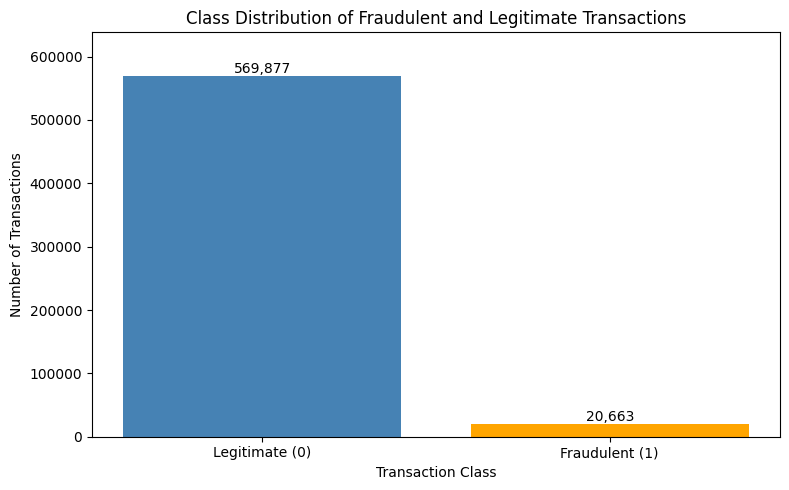

In [11]:

# Visualise the distribution of the legitimate and fraudulent transactions

labels = ["Legitimate (0)", "Fraudulent (1)"]
counts = [fraud_counts[0], fraud_counts[1]]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, counts, color=["steelblue", "orange"])

# Display the number of transactions above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.title("Class Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.ylim(0, max(counts) * 1.12)
plt.tight_layout()
plt.show()



**Observation:**
The graph shows that the dataset is imbalanced. Legitimate transactions account for 96.5% of the data, while fraudulent transactions account for only 3.5%. This means that the model may learn more from legitimate transactions because they are more common. Therefore, I will investigate the different techniques for handling class imbalance when developing fraud detection models.




### 1.6 Transaction Amount Analysis

In this section, I have examine the transaction amounts in the dataset. The purpose is to understand how transaction amounts are distributed and compare legitimate and fraudulent transactions. This will help me to investigate whether transaction amount may be useful when developing of the fraud detection models.


In [12]:

# Examine the transaction amounts in the dataset

print("Transaction Amount Summary:")

print(df["TransactionAmt"].describe())


Transaction Amount Summary:
count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64


**Observation**

The data said it contains 590,540 transactions, with the average transaction amount of 135.03 and the median of 68.77. The maximum transaction amount it is 31,937.39 which it is much higher than the average. And this suggests that some of the transactions health usually high amounts. And additional analysis will compare the legitimate and fraudulent transaction to understand whether the transaction amounts it may help in the detecting of the fraud.


In [13]:
# Comparing transaction amounts between legitimate and fraudulent transactions

transaction_comparison = df.groupby("isFraud")["TransactionAmt"].describe()

# Rename of the classes to make the results easier to understand to me
transaction_comparison.index = ["Legitimate (0)", "Fraudulent (1)"]

print("Transaction Amount Comparison by Fraud Class:")

display(transaction_comparison.round(2))

Transaction Amount Comparison by Fraud Class:


,count,mean,std,min,25%,50%,75%,max
Legitimate (0),569877.0,134.51,239.40,0.25,43.97,68.5,120.0,31937.39
Fraudulent (1),20663.0,149.24,232.21,0.29,35.04,75.0,161.0,5191.00


**Observation**

The results show fraudulent transactions are slightly higher than the average amount of 149.24 while compared to 134.34 for the legitimate transactions. The median amount is higher for fraudulent transactions. But the maximum legitimate transaction amount is higher than the maximum fraudulent transaction amount. This suggests that the transaction amounts may be useful for the fraud reduction, but it cannot be used alone to identify the fraudulent transaction.


### 1.6.1 Average Transaction Amount by Fraud Class

In this step I have compared the transaction amount of the legitimate and the fraudulent transaction by using bar chart. And this helps me to understand whether there is a difference in between the transaction amount between the two classes.


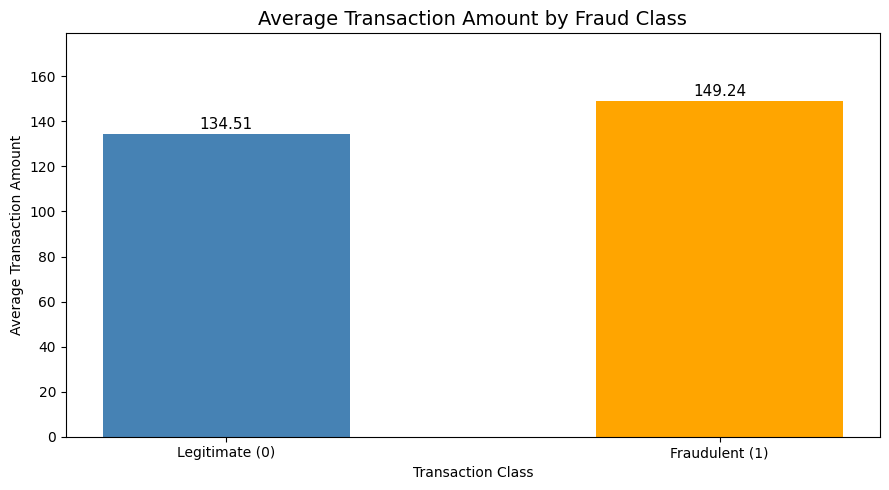

In [14]:

# Calculate average transaction amounts for each class
average_amount = df.groupby("isFraud")["TransactionAmt"].mean()

# Create the bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Legitimate (0)", "Fraudulent (1)"],
    average_amount.reindex([0, 1]),
    color=["steelblue", "orange"],
    width=0.5
)

# Add the values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{height:.2f}",
        ha="center",
        fontsize=11
    )

# Add graph title and labels
plt.title("Average Transaction Amount by Fraud Class", fontsize=14)
plt.xlabel("Transaction Class")
plt.ylabel("Average Transaction Amount")
plt.ylim(0, average_amount.max() * 1.2)

plt.tight_layout()
plt.show()


**Observation**

The graph shows that fraudulent transactions have the higher average amount of 149.24 while compared to 134.34 for the legitimate transactions. This suggests that the transactions amount it can help to differentiate between the fraudulent and the legitimate transactions. But transaction amount alone is not enough to detect fraud accurately, so the other feature will be also considered during the development of model.


### 1.6.2 Distribution of the transaction amount.

In this section, I will be examining how the transaction amount is distributed in the data set. And the purpose is to understand whether most transactions have a small or large amount and identify the possible extreme values that can affect the analysis and the development of the fraud detection models.


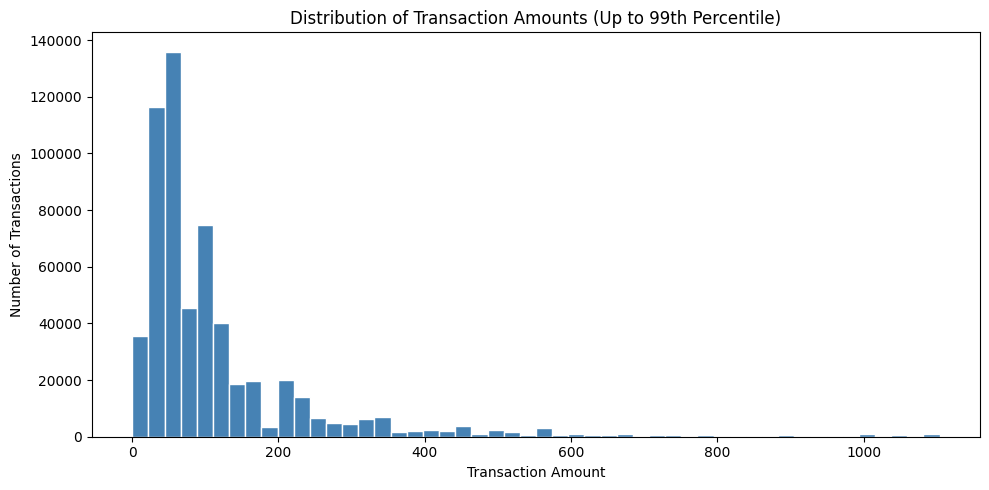

In [15]:

# Visualise the distribution of transaction amounts

# Use the 99th percentile to make the graph easier to read
amount_limit = df["TransactionAmt"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    df.loc[df["TransactionAmt"] <= amount_limit, "TransactionAmt"].dropna(),
    bins=50,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Transaction Amounts (Up to 99th Percentile)")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()


The graph shows that most transactions have relatively small amounts, while only few transactions have very large amounts. And this indicates that the transaction amounts are not eventually distributed and they are positively skewed. The graphics also showed that some of the transactions have unusually high amounts which may affect the performance of the fraud detection models. And therefore, the transaction amounts it may require further investigation and suitable preprocessing before the training of the model.

### 1.6.3 Distribution of the transaction amounts by fraud status

in this session, I will be comparing the transaction amounts of the fraudulent and the non-fraudulent transaction. The purpose is for understanding whether there are differences in the transaction amounts between the two groups and whether the transaction amounts could be useful for the detecting of the fraudulent activities.


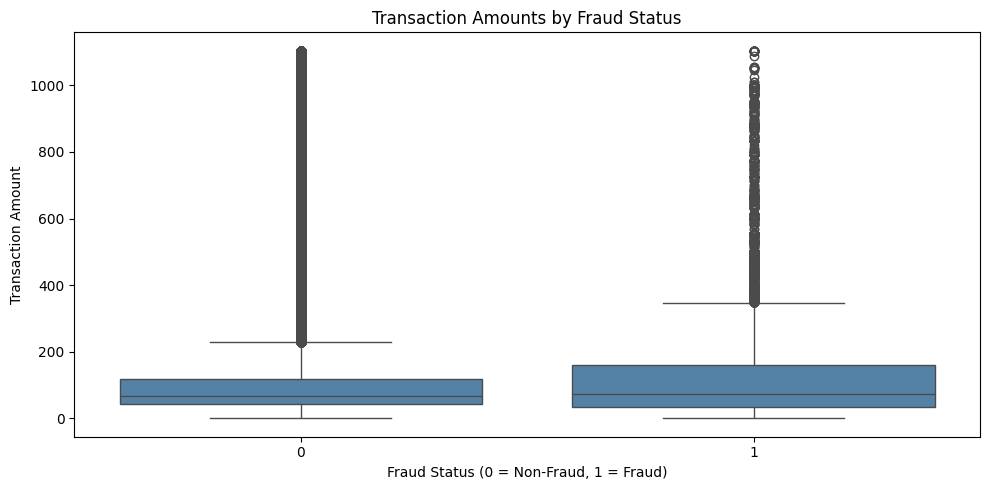

In [16]:
# Compare transaction amounts by fraud status

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Use the 99th percentile for better visualisation
amount_limit = df["TransactionAmt"].quantile(0.99)

sns.boxplot(
    data=df[df["TransactionAmt"] <= amount_limit],
    x="isFraud",
    y="TransactionAmt",
    color="steelblue"
)

plt.title("Transaction Amounts by Fraud Status")
plt.xlabel("Fraud Status (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

**Interpretation of the results**

in the graph it compares the transactions amounts in between the fraudulent and the non-fraudulent transactions. The results show that fraudulent transactions have a wider spread for the transaction amounts compared to the non-fraudulent transactions. Support groups contain unusually high transaction amounts which indicate the presence of the outliers. This is the suggestion that the transaction amount may be useful in identifying fraud patterns, but it cannot be used alone in order to determine whether the transaction is fraudulent. And therefore, features will be considered when developing the fraud detection model.


### 1.6.4 Missing values analysis

 in this session, I will examine the missing of the values in the fraud detection dataset. And the purpose is to identify the features with the missing of the information and also understand how these missing values it may affect the development of the fraud detection models and this analysis will help to determine the appropriate of the data preprocessing technique require before the model training.


Top 20 columns with missing values:


,Missing Values,Missing Percentage
dist2,552913,93.628374
D7,551623,93.409930
D13,528588,89.509263
D14,528353,89.469469
D12,525823,89.041047
D6,517353,87.606767
D8,515614,87.312290
D9,515614,87.312290
V154,508595,86.123717
V153,508595,86.123717


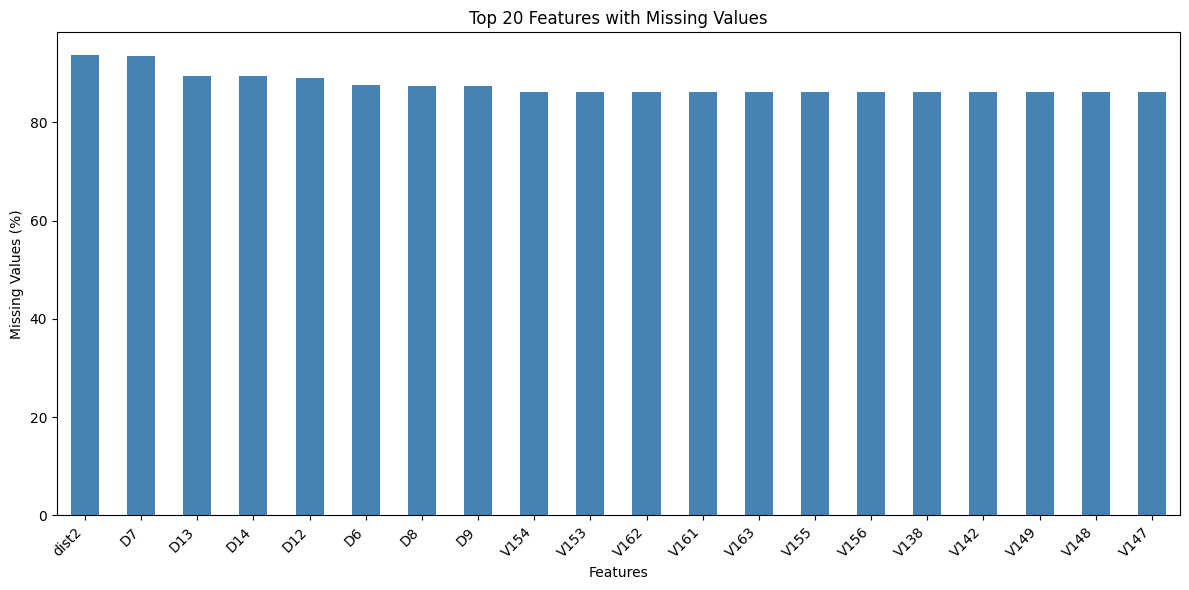

In [17]:
# Analyse missing values in the fraud detection dataset

import pandas as pd
import matplotlib.pyplot as plt

# Calculate missing values for each column
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Keep columns containing missing values
missing_df = missing_df[
    missing_df["Missing Values"] > 0
]

# Sort from highest to lowest
missing_df = missing_df.sort_values(
    by="Missing Percentage",
    ascending=False
)

# Display top 20 columns
print("Top 20 columns with missing values:")
display(missing_df.head(20))

# Plot top 20 columns
plt.figure(figsize=(12, 6))

missing_df.head(20)["Missing Percentage"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretation of the results**

The missing values of the analysis show that the several features in the dataset contain a high percentage of the missing information. Future dist2 has the highest percentage of the missing values at approximately 93, 63%, and it is followed by D7 at 93, 41%. And the other features, which include the D13, D14, D12 and V features have also contained a large amount of the missing data. This results it indicate that the missing values are an important issue that must be considered during the data preprocessing. The appropriate methods will be investigated to handle the missing values while also preserving the useful information for the fraud detection.


### 1.6.5 The missing values of fraud status.
In this section I will examine whether the missing value is different between it is differ in between the fraudulent and the non-fraudulent transactions. And the purpose is to understand whether the missing information may be associated with the fraudulent activities. And this analysis will help to identify potentially useful features for the development of fraud detection models.


Missing values by fraud status (%):


,Non-Fraud,Fraud
dist2,94.05,81.94
D7,94.19,71.98
D13,90.33,66.91
D14,90.35,65.09
D12,89.98,63.23
D6,88.51,62.65
D8,88.23,62.12
D9,88.23,62.12
V154,86.26,82.34
V153,86.26,82.34


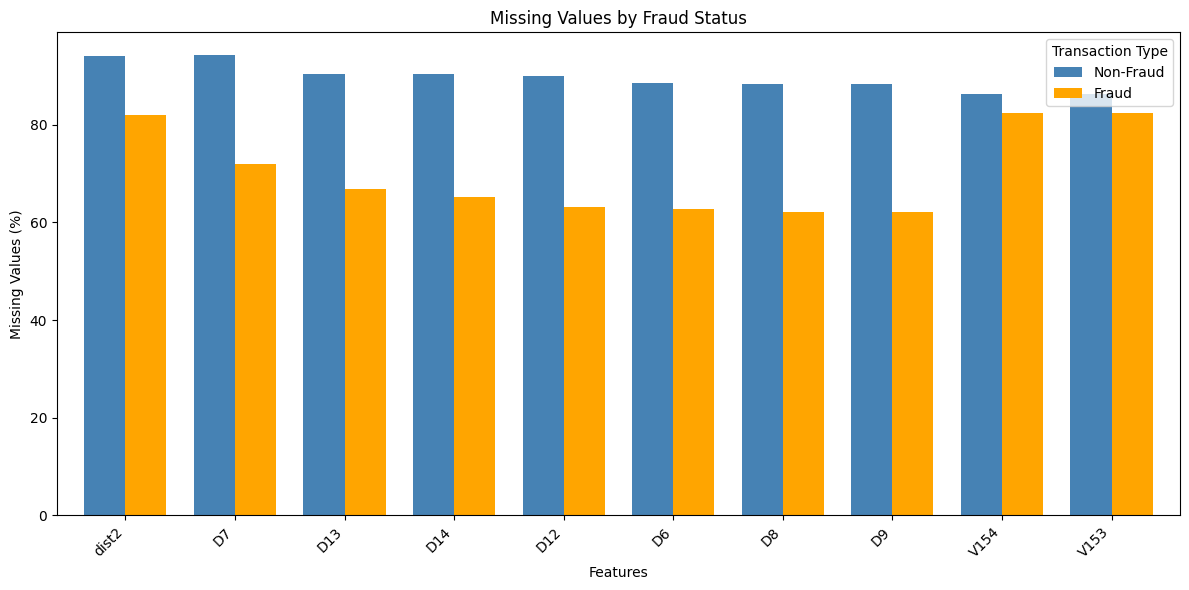

In [18]:
# Compare missing values between fraud and non-fraud transactions

import pandas as pd
import matplotlib.pyplot as plt

# Select the top 10 features with missing values
top_features = missing_df.head(10).index.tolist()

# Calculate missing percentages for each fraud group
missing_by_fraud = (
    df.groupby("isFraud")[top_features]
    .agg(lambda x: x.isna().mean() * 100)
    .T
)

# Rename columns
missing_by_fraud.columns = [
    "Non-Fraud" if col == 0 else "Fraud"
    for col in missing_by_fraud.columns
]

# Display results
print("Missing values by fraud status (%):")
display(missing_by_fraud.round(2))

# Create graph
ax = missing_by_fraud.plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "orange"],
    width=0.75
)

plt.title("Missing Values by Fraud Status")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Transaction Type")
plt.tight_layout()
plt.show()

**The interpretation of the results.**

The graph compares the percentage of the missing values in between the fraudulent and the non-fraudulent transactions. The results also show that non-fraudulent transactions generally have a higher percentage of the missing values across the selected features. For example, D12 has approximately 89, 98% of the missing values in non-fraudulent transactions while compared to 63, 23% in the fraudulent transactions. These differences suggest that the missing of information may contain useful patterns for the fraud deduction. And therefore, the missing values will be carefully considered during the data preprocessing rather than the automatically removing features with the highest of the missing percentage.


### 1.6.6 Transaction of the pattern over the time

in this section, I will be examining on how the transaction activity, and the fraud rates change over the time. And the purpose of this is to identify the possible changes in the transaction pattern and to understand why time-based data splitting is important for fraud detection. This analysis will help to guide the preparation of the training, validation and the testing dataset.


,Total_Transactions,Fraud_Transactions,Fraud_Rate
Day,,,
1,5122,112,2.186646
2,3730,123,3.297587
3,3241,92,2.838630
4,4036,115,2.849356
5,3964,127,3.203835


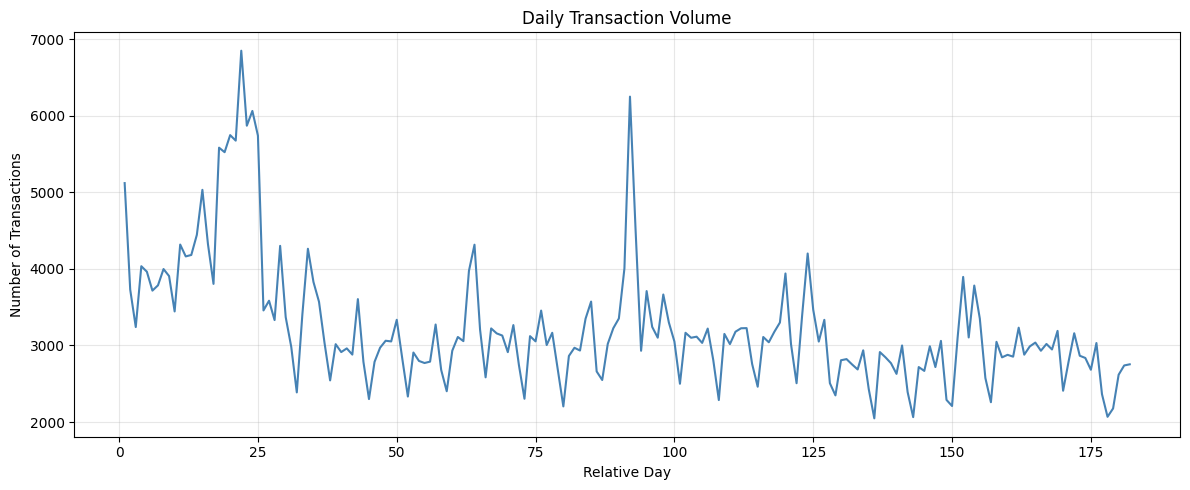

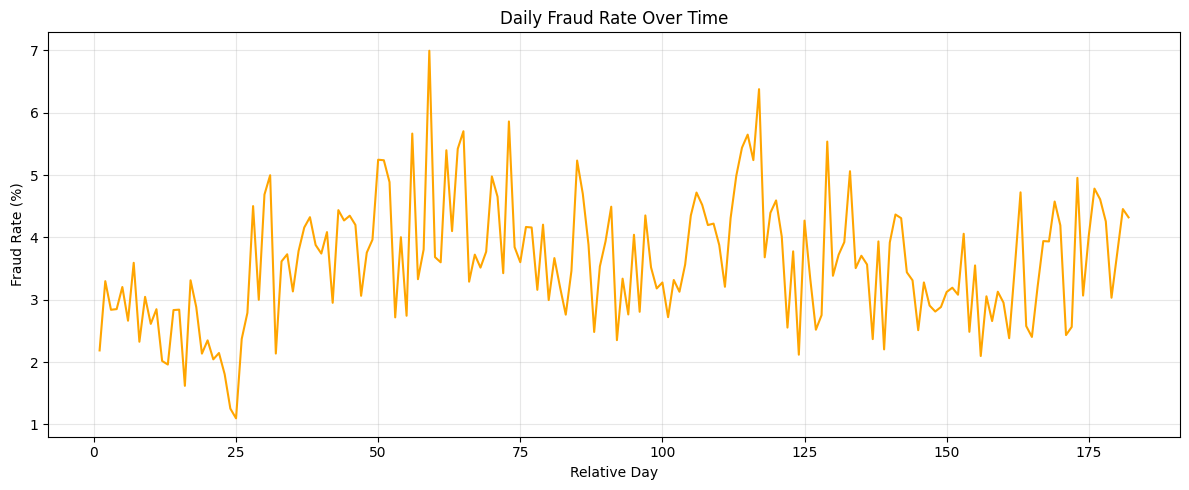

In [19]:
# Analyse transaction patterns over time

import pandas as pd
import matplotlib.pyplot as plt

# Use only the columns needed to reduce memory usage
time_df = df[["TransactionDT", "isFraud"]].copy()

# Convert elapsed seconds into relative days
time_df["Day"] = (
    time_df["TransactionDT"] // 86400
).astype("int32")

# Calculate daily transaction counts and fraud rates
daily_summary = time_df.groupby("Day").agg(
    Total_Transactions=("isFraud", "size"),
    Fraud_Transactions=("isFraud", "sum")
)

daily_summary["Fraud_Rate"] = (
    daily_summary["Fraud_Transactions"]
    / daily_summary["Total_Transactions"] * 100
)

# Display first five days
display(daily_summary.head())

# Create transaction volume graph
plt.figure(figsize=(12, 5))

plt.plot(
    daily_summary.index,
    daily_summary["Total_Transactions"],
    color="steelblue"
)

plt.title("Daily Transaction Volume")
plt.xlabel("Relative Day")
plt.ylabel("Number of Transactions")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Create daily fraud rate graph
plt.figure(figsize=(12, 5))

plt.plot(
    daily_summary.index,
    daily_summary["Fraud_Rate"],
    color="orange"
)

plt.title("Daily Fraud Rate Over Time")
plt.xlabel("Relative Day")
plt.ylabel("Fraud Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation of the daily transaction for volume.**

The graph shows how the number of the transaction changes over time. The daily transaction volumes some of the earlier days were higher, whereas most transactions for loans later days recorded lower transaction volumes. The fraud rates also change throughout the period, with some of the days showing the higher front percentage than the others. This suggests that fraud does not occur at a constant rate. And understanding this pattern is important since it is helped to identify the changes in the front to land activities and support the development of the fraud detection models.


### 1.7 A summary of the exploration data analysis

The exploration data analysis has been conducted using the IEEE-CIS fraud detection dataset to understand the characteristics of the financial transactions and to identify the challenges that may affect the fraud detection models.

The data set contains 590,540 Transactions and 394 columns. The analysis it showed that fraudulent transaction account for approximately 3,5% of the dataset, whereas most of the transactions are legitimate. This indicates that the glass imbalance that must be Considered when developing the models.

The transactions amount to analysis, it shows that most transactions involve relatively small amounts, whereas a smaller number have high value. The comparison between the fraudulent and the non-fraudulent transactions also showed the differences in between the amount distributions.

The missing values analysis has identified several features with the highest percentages of the missing data, including dist2 and D7. Some of the future also showed the different methane patterns in between fraudulent and non-fraudulent transactions. And these findings highlight the importance of the handling of the missing values carefully during the preprocessing.

The time-based analysis has shown that the transaction volume and the fraud rates changed over the observation. This supports the need for the use of chronological training and testing split and to evaluate the performance of the model on the later transactions. On the later transactions
and therefore, the exploratory analysis has identified Glass imbalance, missing values, the transaction amount variation as well as the temporal changes as the important considerations. And these findings will guide the preprocessing model development and then evaluate the stage of the project.
